Broadband noise generation + spectral shaping, and PSD estimation using Welch’s method or periodogram

In [7]:
import numpy as np
def make_spectrum(signal, fs):
    """
    Compute the spectrum of a signal using the Fast Fourier Transform (FFT).
    Extracts the single-sided spectrum up to the Nyquist frequency (fs/2) and scales it appropriately
    Parameters:
    signal (numpy.ndarray): Input signal for which the spectrum is to be computed.
    fs (int): Sampling frequency in Hz.

    Returns:
    Y (numpy.ndarray): Complex-valued spectrum of the input signal.
    freq (numpy.ndarray): Frequency vector corresponding to the spectrum.
    """
    N = len(signal)

    # compute spectrum (note: it will be complex-valued)
    Y = np.fft.fft(signal)
    # The FFT needs to be scaled in order to give a physically plausible scaling.
    Y = Y / N
    # NOTE: If you do an IFFT, this scaling must NOT be done.
    # We’ll get to this in the lecture. If you are only interested
    # in the positive frequencies, you need to scale by <len(Y)/2>.
    # ...
    # frequency vector
    delta_f = fs / N
    # N_0 = T_0/T -> T_0 = 1/fs 
    # T er samplings intervallet i sek T = 1/fs
    # T_0 er signalets længde i sek

    freq = np.arange(0, N) * delta_f
    # NOTE: The first element that comes out of the FFT is the DC offset
    # (i.e., frequency 0). Each subsequent bin is spaced by the
    # frequency resolution <delta_f>, which you can calculate from
    # the properties of the input signal. Remember the highest
    # frequency you can get in a digitized signal.... - the nyquist frequency. The FFT will give you both positive and negative frequencies, but the negative frequencies are just a mirror image of the positive frequencies.
    # So, if you are only interested in the positive frequencies, you can just take the first half of the spectrum and scale it by 2 (except for the DC component).

    # Extract single-sided spectrum up to Nyquist (fs / 2)
    half_N = N // 2 # // giver floor division, så vi får et helt tal
    freq_single = freq[:half_N +1].copy()
    Y_single = Y[:half_N+1].copy()

    if N % 2 == 0:
        # For even N, the last bin is Nyquist (fs/2), which is unique (do not double)
        Y_single[1:-1] *= 2
    else:
        # For odd N, there is no exact Nyquist bin
        Y_single[1:] *= 2
    return Y_single, freq_single


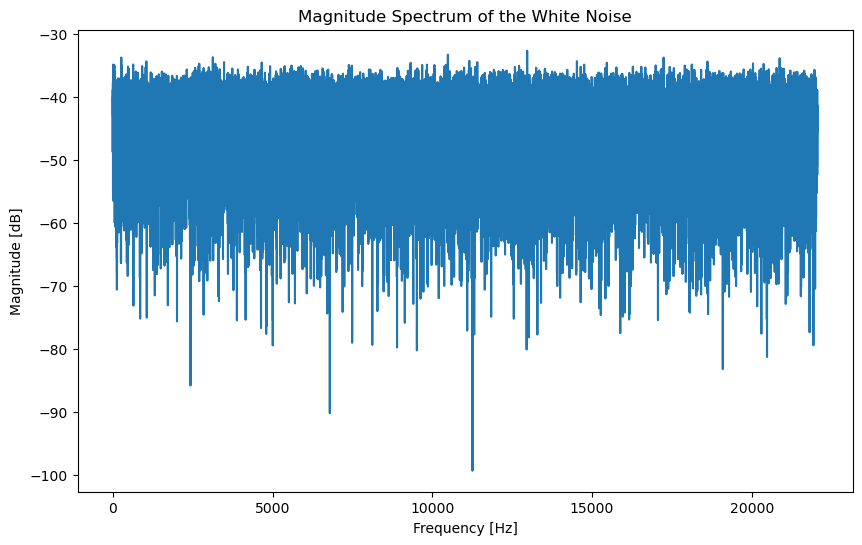

In [ ]:
import numpy as np
import scipy.signal as signal
import scipy.signal.windows as windows
import matplotlib.pyplot as plt

fs = 44100 # Sampling frequency
lengt_s = 2 

noise = np.random.normal(-1, 1, lengt_s * fs) # Generate white noise

Y, freq = make_spectrum(noise, fs)

fft_db = 20 * np.log10(np.abs(Y))

plt.figure(figsize=(10, 6))
plt.plot(freq, fft_db)
plt.title('Magnitude Spectrum of the White Noise')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude [dB]')
plt.show()

In [9]:
from IPython.display import Audio
Audio(noise, rate=fs)

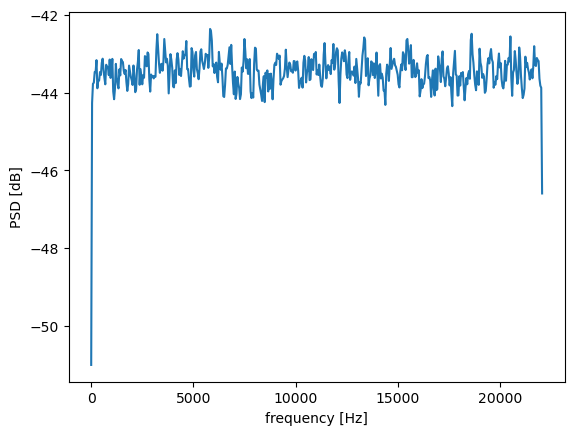

In [10]:
#PSD estumation using Welch's method

f, Pxx_den = signal.welch(noise, fs, nperseg=1024)

Pxx_den_db = 10 * np.log10(Pxx_den)
plt.plot(f, Pxx_den_db)
plt.xlabel('frequency [Hz]')
plt.ylabel('PSD [dB]')
plt.show()

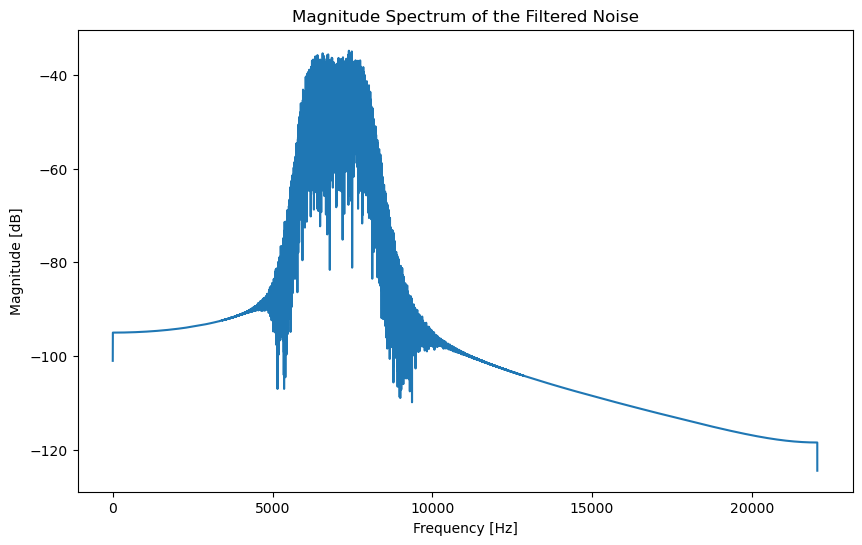

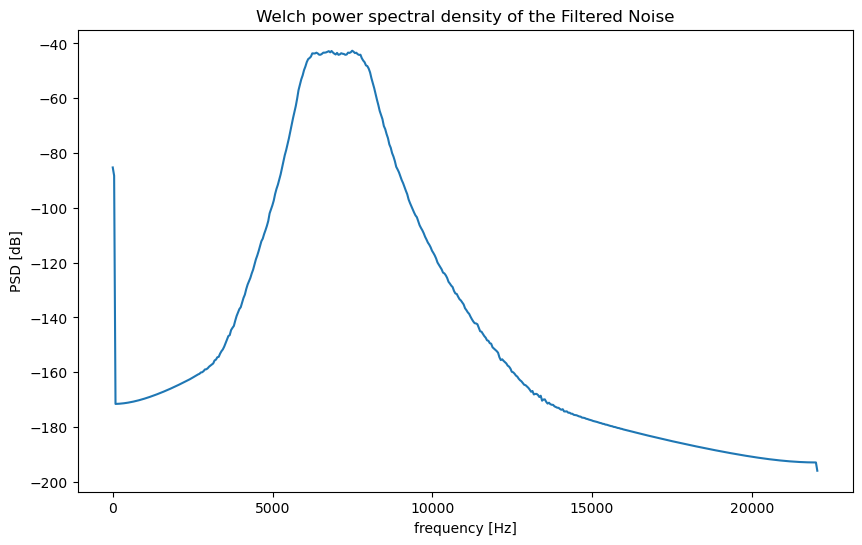

In [11]:
# apply a bandpass filter (6-8 KHz) to the noise signal  

b,a = signal.iirfilter(4, [6000, 8000], fs=fs, btype='band', ftype='butter')
filtered_noise = signal.filtfilt(b, a, noise)

Y, freq = make_spectrum(filtered_noise, fs)

fft_db = 20 * np.log10(np.abs(Y))

plt.figure(figsize=(10, 6))
plt.plot(freq, fft_db)
plt.title('Magnitude Spectrum of the Filtered Noise')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude [dB]')
plt.show()


f, Pxx_den = signal.welch(filtered_noise, fs, nperseg=1024)
Pxx_den_db = 10 * np.log10(Pxx_den)
plt.figure(figsize=(10, 6))
plt.plot(f, Pxx_den_db)
plt.title('Welch power spectral density of the Filtered Noise')
plt.xlabel('frequency [Hz]')
plt.ylabel('PSD [dB]') # The peak height in the power spectrum is an estimate of the RMS amplitude
plt.show()
Audio(filtered_noise, rate=fs)


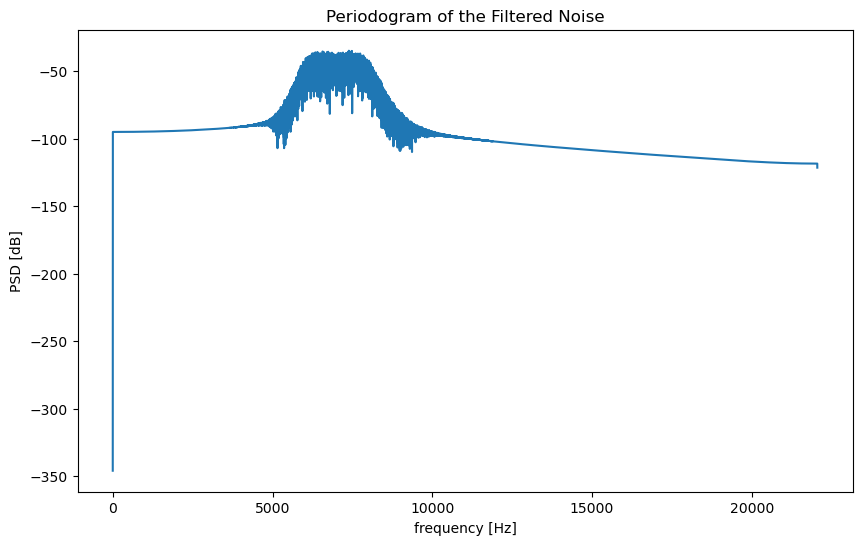

In [12]:
# periodogram of the filtered noise signal
f, Pxx_den = signal.periodogram(filtered_noise, fs)

Pxx_den_db = 10 * np.log10(Pxx_den)

plt.figure(figsize=(10, 6))
plt.plot(f, Pxx_den_db)
plt.title('Periodogram of the Filtered Noise')
plt.xlabel('frequency [Hz]')
plt.ylabel('PSD [dB]')
plt.show()